In [1]:
from pathlib import Path

# The notebook should be in your DeepLearningPro project folder.
PROJECT_DIR = Path.cwd()

# Raw: downloaded files.
# Processed: prepared training images and label masks.
# Metadata: dataset descriptions and train/validation/test file lists.
folders = [
    "data/raw",
    "data/processed",
    "data/metadata",
    "weights",
    "results",
]

for folder in folders:
    path = PROJECT_DIR / folder
    path.mkdir(parents=True, exist_ok=True)
    print(f"Ready: {path}")

print("\nProject folder:", PROJECT_DIR)

Ready: /home/jovyan/vault/DeepLearningPro/data/raw
Ready: /home/jovyan/vault/DeepLearningPro/data/processed
Ready: /home/jovyan/vault/DeepLearningPro/data/metadata
Ready: /home/jovyan/vault/DeepLearningPro/weights
Ready: /home/jovyan/vault/DeepLearningPro/results

Project folder: /home/jovyan/vault/DeepLearningPro


In [2]:
import json

# Record our data decisions so we can explain them in the report.
# None means a decision has not been made yet.
dataset_plan = {
    "dataset": "SEN12MS",
    "official_download_page": "https://mediatum.ub.tum.de/1474000",
    "task": "pixel-level land-cover semantic segmentation",
    "model_inputs": ["Sentinel-1 VV", "Sentinel-1 VH"],
    "label_source": "SEN12MS MODIS-derived land-cover maps",
    "use_sentinel_2_as_model_input": False,
    "class_mapping": None,
    "training_validation_test_split": None,
    "monthly_case_study_location": None,
    "independent_case_study_reference": None,
    "limitations": [
        "Reference labels are coarse and can contain errors.",
        "Training patches alone do not supply the required monthly prototype.",
    ],
}

plan_path = PROJECT_DIR / "data/metadata/dataset_plan.json"

with plan_path.open("w", encoding="utf-8") as file:
    json.dump(dataset_plan, file, indent=2)

print("Saved dataset plan:", plan_path)

Saved dataset plan: /home/jovyan/vault/DeepLearningPro/data/metadata/dataset_plan.json


In [3]:
from pathlib import Path
from urllib.request import Request, urlopen
import shutil
import time


def download_file(url, filename, minimum_free_gb):
    """Download a file in chunks without loading it all into memory."""
    destination = Path("data/raw")
    destination.mkdir(parents=True, exist_ok=True)

    final_path = destination / filename
    partial_path = destination / (filename + ".part")

    # Protect an existing download from accidental replacement.
    if final_path.exists():
        print("File already exists:", final_path)
        print("We will verify it before using it.")
        return final_path

    free_gb = shutil.disk_usage(destination).free / 1_000_000_000
    if free_gb < minimum_free_gb:
        raise RuntimeError(
            f"Only {free_gb:.1f} GB free. "
            f"At least {minimum_free_gb} GB is required for this step."
        )

    request = Request(url, headers={"User-Agent": "LULC-student-project/1.0"})

    print("Starting:", filename, flush=True)
    downloaded = 0
    last_update = time.monotonic()

    # A .part file means the download has not finished.
    # Rerunning after a failure restarts the download from the beginning.
    with urlopen(request, timeout=60) as response:
        content_type = response.headers.get("Content-Type", "").lower()
        if "text/html" in content_type:
            raise ValueError(
                "The link returned a webpage. Copy the individual "
                "file's download link instead."
            )

        expected_size = response.headers.get("Content-Length")
        expected_size = int(expected_size) if expected_size else None

        with partial_path.open("wb") as output:
            while True:
                chunk = response.read(1024 * 1024)
                if not chunk:
                    break

                output.write(chunk)
                downloaded += len(chunk)

                if time.monotonic() - last_update >= 5:
                    print(
                        f"Downloaded {downloaded / 1_000_000:.1f} MB",
                        flush=True,
                    )
                    last_update = time.monotonic()

    if expected_size is not None and downloaded != expected_size:
        raise IOError("Incomplete download. Run the download cell again.")

    # These archives should have the gzip file signature.
    with partial_path.open("rb") as downloaded_file:
        if downloaded_file.read(2) != b"\x1f\x8b":
            raise ValueError("Downloaded content is not a gzip archive.")

    partial_path.replace(final_path)
    print("Download finished:", final_path)
    print("Next we will verify its checksum and inspect its contents.")
    return final_path

In [4]:
# Run this cell, then paste the copied download link into the input box.
label_url = input("Paste the winter lc download link: ").strip()

label_file = download_file(
    url=label_url,
    filename="ROIs2017_winter_lc.tar.gz",
    minimum_free_gb=1,
)

KeyboardInterrupt: Interrupted by user

In [5]:
from pathlib import Path

file = Path("data/raw/ROIs2017_winter_lc.tar.gz")

print("Notebook working folder:", Path.cwd())

if file.exists():
    print("File found:", file.resolve())
    print(f"Size: {file.stat().st_size / 1_000_000:.1f} MB")
else:
    print("File not found at the expected location.")

Notebook working folder: /home/jovyan/vault/DeepLearningPro
File found: /home/jovyan/vault/DeepLearningPro/data/raw/ROIs2017_winter_lc.tar.gz
Size: 48.2 MB


In [6]:
import tarfile
from pathlib import Path

archive = Path("data/raw/ROIs2017_winter_lc.tar.gz")

with tarfile.open(archive, "r:gz") as contents:
    for index, member in enumerate(contents):
        if index == 5:
            break
        print(member.name)

print("Archive opened successfully.")

ROIs2017_winter/lc_102
ROIs2017_winter/lc_102/ROIs2017_winter_lc_102_p316.tif
ROIs2017_winter/lc_102/ROIs2017_winter_lc_102_p537.tif
ROIs2017_winter/lc_102/ROIs2017_winter_lc_102_p100.tif
ROIs2017_winter/lc_102/ROIs2017_winter_lc_102_p101.tif
Archive opened successfully.


In [12]:
from pathlib import Path
import hashlib

# Files already uploaded into Data Lab.
raw_dir = Path("data/raw")
archive = raw_dir / "ROIs2017_winter_lc.tar.gz"
checksum_file = raw_dir / "checksums.sha512"

# Confirm both files exist.
for path in (archive, checksum_file):
    if not path.is_file():
        raise FileNotFoundError(f"Missing file: {path.resolve()}")

print(f"Archive size: {archive.stat().st_size / 1_000_000:.1f} MB")

# Find this archive's fingerprint in the publisher's checksum list.
expected_hash = None

for line in checksum_file.read_text(encoding="utf-8").splitlines():
    parts = line.strip().split(maxsplit=1)

    if len(parts) != 2:
        continue

    checksum, filename = parts
    filename = filename.lstrip("*")

    if Path(filename).name == archive.name:
        expected_hash = checksum.lower()
        break

if expected_hash is None:
    raise ValueError(
        "Archive name not found in checksums.sha512. "
        "Share this error so we can inspect the checksum file."
    )

# Calculate the downloaded file's fingerprint.
hasher = hashlib.sha512()

with archive.open("rb") as source:
    for chunk in iter(lambda: source.read(1024 * 1024), b""):
        hasher.update(chunk)

# Matching fingerprints confirm the file matches the publisher's copy.
if hasher.hexdigest() != expected_hash:
    raise ValueError(
        "Checksum mismatch. Do not extract the archive yet."
    )

print("PASS: label archive matches the publisher's SHA-512 checksum.")

Archive size: 48.2 MB
PASS: label archive matches the publisher's SHA-512 checksum.


In [11]:
from pathlib import Path
import hashlib

In [13]:
from urllib.request import Request, urlopen

s1_url = (
    "https://dataserv.ub.tum.de/s/m1474000/download"
    "?path=%2F&files=ROIs2017_winter_s1.tar.gz"
)

request = Request(s1_url, headers={"User-Agent": "LULC-student-project/1.0"})

with urlopen(request, timeout=60) as response:
    signature = response.read(2)

if signature == b"\x1f\x8b":
    print("PASS: the URL returns a gzip archive.")
else:
    raise ValueError("The URL did not return the expected archive.")

PASS: the URL returns a gzip archive.


In [14]:
s1_file = download_file(
    url=s1_url,
    filename="ROIs2017_winter_s1.tar.gz",
    minimum_free_gb=50,
)

Starting: ROIs2017_winter_s1.tar.gz
Downloaded 15.7 MB
Downloaded 232.8 MB
Downloaded 464.5 MB
Downloaded 690.0 MB
Downloaded 919.6 MB
Downloaded 1162.9 MB
Downloaded 1396.7 MB
Downloaded 1631.6 MB
Downloaded 1873.8 MB
Downloaded 2119.2 MB
Downloaded 2365.6 MB
Downloaded 2613.1 MB
Downloaded 2858.4 MB
Downloaded 3101.7 MB
Downloaded 3342.9 MB
Downloaded 3580.9 MB
Downloaded 3826.3 MB
Downloaded 4065.3 MB
Downloaded 4307.6 MB
Downloaded 4548.7 MB
Downloaded 4788.8 MB
Downloaded 5027.9 MB
Downloaded 5275.4 MB
Downloaded 5513.4 MB
Downloaded 5754.6 MB
Downloaded 5998.9 MB
Downloaded 6243.2 MB
Downloaded 6485.4 MB
Downloaded 6725.6 MB
Downloaded 6967.8 MB
Downloaded 7211.1 MB
Downloaded 7452.2 MB
Downloaded 7685.0 MB
Downloaded 7925.1 MB
Downloaded 8170.5 MB
Downloaded 8413.8 MB
Downloaded 8652.8 MB
Downloaded 8899.3 MB
Downloaded 9136.2 MB
Downloaded 9379.5 MB
Downloaded 9612.3 MB
Downloaded 9855.6 MB
Downloaded 10095.7 MB
Downloaded 10341.1 MB
Downloaded 10583.3 MB
Downloaded 10828.6 MB


In [15]:
from pathlib import Path
import hashlib

archive = Path("data/raw/ROIs2017_winter_s1.tar.gz")
checksum_file = Path("data/raw/checksums.sha512")

# Find the publisher's expected fingerprint.
expected_hash = None

for line in checksum_file.read_text(encoding="utf-8").splitlines():
    parts = line.strip().split(maxsplit=1)

    if len(parts) == 2:
        checksum, filename = parts
        if Path(filename.lstrip("*")).name == archive.name:
            expected_hash = checksum.lower()
            break

if expected_hash is None:
    raise ValueError("Imagery archive not found in the checksum list.")

print("Checking the imagery archive. This may take a few minutes.", flush=True)

hasher = hashlib.sha512()

with archive.open("rb") as source:
    for chunk in iter(lambda: source.read(8 * 1024 * 1024), b""):
        hasher.update(chunk)

if hasher.hexdigest() != expected_hash:
    raise ValueError("Checksum mismatch. Do not extract this archive yet.")

print("PASS: Sentinel-1 archive matches the publisher's checksum.")

Checking the imagery archive. This may take a few minutes.
PASS: Sentinel-1 archive matches the publisher's checksum.


In [17]:
from pathlib import Path
import tarfile
import shutil

raw_dir = Path("data/raw")
extract_dir = Path("data/extracted")
extract_dir.mkdir(parents=True, exist_ok=True)

archive_names = [
    "ROIs2017_winter_lc.tar.gz",
    "ROIs2017_winter_s1.tar.gz",
]

for archive_name in archive_names:
    archive_path = raw_dir / archive_name
    marker = extract_dir / (archive_name + ".complete")

    if marker.exists():
        print("Already extracted:", archive_name)
        continue

    if not archive_path.is_file():
        raise FileNotFoundError(f"Missing archive: {archive_path}")

    print("Extracting:", archive_name, flush=True)
    count = 0

    with tarfile.open(archive_path, "r:gz") as archive:
        for member in archive:
            # We need only regular GeoTIFF files.
            if not member.isfile():
                continue
            if not member.name.lower().endswith((".tif", ".tiff")):
                continue

            # Ensure the output stays inside our extraction folder.
            target = (extract_dir / member.name).resolve()
            if not target.is_relative_to(extract_dir.resolve()):
                raise ValueError(f"Unexpected archive path: {member.name}")

            target.parent.mkdir(parents=True, exist_ok=True)

            # Allow an interrupted extraction to resume.
            if target.exists() and target.stat().st_size == member.size:
                count += 1
                continue

            if shutil.disk_usage(extract_dir).free < member.size + 1_000_000_000:
                raise RuntimeError("Insufficient free disk space for extraction.")

            source = archive.extractfile(member)
            if source is None:
                raise RuntimeError(f"Cannot read: {member.name}")

            partial = target.with_suffix(target.suffix + ".part")
            with source, partial.open("wb") as output:
                shutil.copyfileobj(source, output)

            if partial.stat().st_size != member.size:
                raise IOError(f"Incomplete extraction: {member.name}")

            partial.replace(target)
            count += 1

            if count % 2000 == 0:
                print(f"  Extracted {count:,} TIFF files", flush=True)

    if count == 0:
        raise ValueError("No TIFF files found in this archive.")

    marker.write_text(f"{count} TIFF files extracted\n", encoding="utf-8")
    print(f"Finished: {count:,} TIFF files", flush=True)

print("Extraction complete.")

Already extracted: ROIs2017_winter_lc.tar.gz
Already extracted: ROIs2017_winter_s1.tar.gz
Extraction complete.


In [19]:
from pathlib import Path

dataset_dir = Path("data/extracted/ROIs2017_winter")
s1_files = sorted(dataset_dir.rglob("*_s1_*.tif"))

pairs = []
missing_labels = []

for image_path in s1_files:
    # Replace s1 with lc in both the folder and filename.
    relative_path = image_path.relative_to(dataset_dir)
    label_path = dataset_dir / str(relative_path).replace("s1_", "lc_")

    if label_path.is_file():
        pairs.append((image_path, label_path))
    else:
        missing_labels.append(image_path)

print("Sentinel-1 patches:", len(s1_files))
print("Matched image–label pairs:", len(pairs))
print("Images without labels:", leimport numpy as np
import rasterio
import matplotlib.pyplot as plt

image_path, label_path = pairs[0]

with rasterio.open(image_path) as image_source:
    image = image_source.read(masked=True)
    image_crs = image_source.crs
    image_transform = image_source.transform

with rasterio.open(label_path) as label_source:
    labels = label_source.read(masked=True)
    label_crs = label_source.crs
    label_transform = label_source.transform
    label_descriptions = label_source.descriptions

print("Image shape (channels, height, width):", image.shape)
print("Label shape (bands, height, width):", labels.shape)
print("Label band descriptions:", label_descriptions)
print("First label-band IDs:", np.unique(labels[0].compressed()))

# Check that pixels refer to the same geographic grid.
aligned = (
    image.shape[1:] == labels.shape[1:]
    and image_crs is not None
    and image_crs == label_crs
    and image_transform.almost_equals(label_transform)
)

print("Matching geographic grids:", aligned)

if not aligned:
    raise ValueError("Image and label grids need inspection before training.")

if image.shape[0] != 2:
    raise ValueError("Expected two Sentinel-1 channels. Share the printed shapes.")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for channel in range(2):
    values = image[channel].compressed()
    values = values[np.isfinite(values)]

    if values.size == 0:
        raise ValueError(f"Channel {channel + 1} has no finite valid values.")

    low, high = np.percentile(values, [2, 98])

    axes[channel].imshow(
        image[channel],
        cmap="gray",
        vmin=low,
        vmax=high if high > low else low + 1,
    )
    axes[channel].set_title(f"Sentinel-1 channel {channel + 1}")

axes[2].imshow(labels[0], cmap="tab20", interpolation="nearest")
axes[2].set_title("Reference labels — band 1")

for axis in axes:
    axis.axis("off")

plt.tight_layout()
plt.show()n(missing_labels))

if not pairs:
    raise ValueError("No matching pairs found. Share this output.")

print("\nExample image:", pairs[0][0])
print("Example label:", pairs[0][1])

Sentinel-1 patches: 31825
Matched image–label pairs: 31825
Images without labels: 0

Example image: data/extracted/ROIs2017_winter/s1_102/ROIs2017_winter_s1_102_p100.tif
Example label: data/extracted/ROIs2017_winter/lc_102/ROIs2017_winter_lc_102_p100.tif


Image shape (channels, height, width): (2, 256, 256)
Label shape (bands, height, width): (4, 256, 256)
Label band descriptions: (None, None, None, None)
First label-band IDs: [12 14]
Matching geographic grids: True


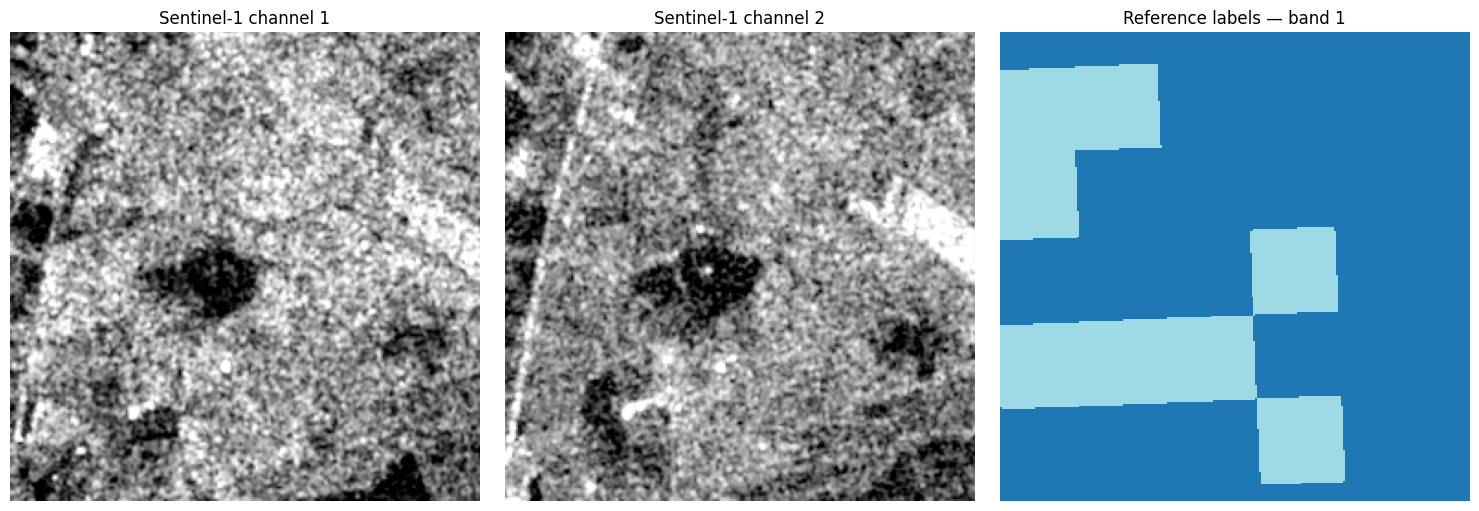

In [20]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt

image_path, label_path = pairs[0]

with rasterio.open(image_path) as image_source:
    image = image_source.read(masked=True)
    image_crs = image_source.crs
    image_transform = image_source.transform

with rasterio.open(label_path) as label_source:
    labels = label_source.read(masked=True)
    label_crs = label_source.crs
    label_transform = label_source.transform
    label_descriptions = label_source.descriptions

print("Image shape (channels, height, width):", image.shape)
print("Label shape (bands, height, width):", labels.shape)
print("Label band descriptions:", label_descriptions)
print("First label-band IDs:", np.unique(labels[0].compressed()))

# Check that pixels refer to the same geographic grid.
aligned = (
    image.shape[1:] == labels.shape[1:]
    and image_crs is not None
    and image_crs == label_crs
    and image_transform.almost_equals(label_transform)
)

print("Matching geographic grids:", aligned)

if not aligned:
    raise ValueError("Image and label grids need inspection before training.")

if image.shape[0] != 2:
    raise ValueError("Expected two Sentinel-1 channels. Share the printed shapes.")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for channel in range(2):
    values = image[channel].compressed()
    values = values[np.isfinite(values)]

    if values.size == 0:
        raise ValueError(f"Channel {channel + 1} has no finite valid values.")

    low, high = np.percentile(values, [2, 98])

    axes[channel].imshow(
        image[channel],
        cmap="gray",
        vmin=low,
        vmax=high if high > low else low + 1,
    )
    axes[channel].set_title(f"Sentinel-1 channel {channel + 1}")

axes[2].imshow(labels[0], cmap="tab20", interpolation="nearest")
axes[2].set_title("Reference labels — band 1")

for axis in axes:
    axis.axis("off")

plt.tight_layout()
plt.show()

In [21]:
from pathlib import Path
from collections import Counter
import random
import csv
import json

project_dir = Path.cwd()
dataset_dir = project_dir / "data/extracted/ROIs2017_winter"
metadata_dir = project_dir / "data/metadata"
metadata_dir.mkdir(parents=True, exist_ok=True)

# Rebuild the inventory from disk so this cell works after a kernel restart.
records = []
missing_labels = []

for image_path in sorted(dataset_dir.rglob("*_s1_*.tif")):
    relative_path = image_path.relative_to(dataset_dir)
    label_path = dataset_dir / str(relative_path).replace("s1_", "lc_")

    if not label_path.is_file():
        missing_labels.append(str(image_path))
        continue

    records.append({
        "image": image_path.relative_to(project_dir).as_posix(),
        "label": label_path.relative_to(project_dir).as_posix(),
        "scene": image_path.parent.name,
    })

if not records:
    raise ValueError("No matching image–label pairs found.")

if missing_labels:
    raise ValueError(
        f"{len(missing_labels)} images have no matching labels. "
        "Share this message before continuing."
    )

# Shuffle whole scenes using a fixed seed for reproducibility.
scenes = sorted({record["scene"] for record in records})

if len(scenes) < 3:
    raise ValueError("At least three scenes are needed for these splits.")

random.Random(42).shuffle(scenes)

# Approximately 70/15/15 by SCENE count, not necessarily by patch count.
n_test = max(1, round(len(scenes) * 0.15))
n_validation = max(1, round(len(scenes) * 0.15))

scene_groups = {
    "test": set(scenes[:n_test]),
    "validation": set(scenes[n_test:n_test + n_validation]),
    "train": set(scenes[n_test + n_validation:]),
}

if not scene_groups["train"]:
    raise ValueError("No scenes remain for training.")

# Confirm that no scene appears in more than one split.
assert scene_groups["train"].isdisjoint(scene_groups["validation"])
assert scene_groups["train"].isdisjoint(scene_groups["test"])
assert scene_groups["validation"].isdisjoint(scene_groups["test"])

for split_name, split_scenes in scene_groups.items():
    split_records = [
        record for record in records if record["scene"] in split_scenes
    ]

    output_path = metadata_dir / f"{split_name}.csv"

    with output_path.open("w", newline="", encoding="utf-8") as output:
        writer = csv.DictWriter(
            output, fieldnames=["image", "label", "scene"]
        )
        writer.writeheader()
        writer.writerows(split_records)

    print(
        f"{split_name}: {len(split_scenes)} scenes, "
        f"{len(split_records):,} patches"
    )

split_description = {
    "seed": 42,
    "method": "custom split by scene folder",
    "season": "winter",
    "label_band": 1,
    "scenes": {
        name: sorted(group) for name, group in scene_groups.items()
    },
}

with (metadata_dir / "split_description.json").open(
    "w", encoding="utf-8"
) as output:
    json.dump(split_description, output, indent=2)

print("\nSaved split CSV files and split_description.json.")

test: 7 scenes, 5,050 patches
validation: 7 scenes, 4,993 patches
train: 32 scenes, 21,782 patches

Saved split CSV files and split_description.json.


In [22]:
import numpy as np
import rasterio
import csv
from collections import Counter

distribution_rows = []

for split_name in ("train", "validation", "test"):
    with (metadata_dir / f"{split_name}.csv").open(
        newline="", encoding="utf-8"
    ) as source:
        split_records = list(csv.DictReader(source))

    counts = Counter()

    for index, record in enumerate(split_records, start=1):
        with rasterio.open(project_dir / record["label"]) as source:
            # Rasterio excludes pixels explicitly marked as missing.
            label_values = source.read(1, masked=True).compressed()

        ids, frequencies = np.unique(label_values, return_counts=True)

        for label_id, frequency in zip(ids, frequencies):
            counts[int(label_id)] += int(frequency)

        if index % 2000 == 0:
            print(
                f"{split_name}: inspected {index:,} label patches",
                flush=True,
            )

    total = sum(counts.values())

    print(f"\n{split_name.upper()} — reference-label pixel counts")
    for label_id, count in sorted(counts.items()):
        percentage = 100 * count / total if total else 0

        print(f"ID {label_id:3}: {count:12,} pixels | {percentage:6.2f}%")

        distribution_rows.append({
            "split": split_name,
            "raw_label_id": label_id,
            "pixel_count": count,
            "percentage_of_unmasked_labels": percentage,
        })

output_path = metadata_dir / "raw_label_distribution.csv"

with output_path.open("w", newline="", encoding="utf-8") as output:
    writer = csv.DictWriter(
        output,
        fieldnames=[
            "split",
            "raw_label_id",
            "pixel_count",
            "percentage_of_unmasked_labels",
        ],
    )
    writer.writeheader()
    writer.writerows(distribution_rows)

print("\nSaved:", output_path)

train: inspected 2,000 label patches
train: inspected 4,000 label patches
train: inspected 6,000 label patches
train: inspected 8,000 label patches
train: inspected 10,000 label patches
train: inspected 12,000 label patches
train: inspected 14,000 label patches
train: inspected 16,000 label patches
train: inspected 18,000 label patches
train: inspected 20,000 label patches

TRAIN — reference-label pixel counts
ID   1:   16,832,523 pixels |   1.19%
ID   2:   11,284,091 pixels |   0.80%
ID   4:   43,548,735 pixels |   3.07%
ID   5:   22,318,026 pixels |   1.57%
ID   6:    5,013,568 pixels |   0.35%
ID   7:  168,622,162 pixels |  11.89%
ID   8:  104,151,225 pixels |   7.35%
ID   9:  210,023,434 pixels |  14.81%
ID  10:  247,090,600 pixels |  17.43%
ID  11:    9,396,514 pixels |   0.66%
ID  12:  237,440,764 pixels |  16.75%
ID  13:  114,381,704 pixels |   8.07%
ID  14:   29,816,638 pixels |   2.10%
ID  16:  127,331,209 pixels |   8.98%
ID  17:   70,550,293 pixels |   4.98%
validation: insp

In [23]:
from pathlib import Path
from collections import Counter
import csv
import json

metadata_dir = Path("data/metadata")

# Model IDs start at 0. Original dataset IDs start at 1.
class_definitions = [
    {"id": 0, "name": "Forest", "source_ids": [1, 2, 3, 4, 5]},
    {"id": 1, "name": "Shrubland", "source_ids": [6, 7]},
    {"id": 2, "name": "Savanna", "source_ids": [8, 9]},
    {"id": 3, "name": "Grassland", "source_ids": [10]},
    {"id": 4, "name": "Wetland", "source_ids": [11]},
    {"id": 5, "name": "Cropland", "source_ids": [12, 14]},
    {"id": 6, "name": "Urban/Built-up", "source_ids": [13]},
    {"id": 7, "name": "Snow/Ice", "source_ids": [15]},
    {"id": 8, "name": "Barren", "source_ids": [16]},
    {"id": 9, "name": "Water", "source_ids": [17]},
]

source_to_model = {
    source_id: definition["id"]
    for definition in class_definitions
    for source_id in definition["source_ids"]
}

with (metadata_dir / "raw_label_distribution.csv").open(
    newline="", encoding="utf-8"
) as source:
    raw_rows = list(csv.DictReader(source))

counts = {
    split: Counter()
    for split in ("train", "validation", "test")
}
ignored_counts = Counter()

for row in raw_rows:
    split = row["split"]
    raw_id = int(row["raw_label_id"])
    count = int(row["pixel_count"])

    # Reserve 255 as the ignored-pixel value for training.
    if raw_id in (0, 255):
        ignored_counts[split] += count
    elif raw_id in source_to_model:
        counts[split][source_to_model[raw_id]] += count
    else:
        raise ValueError(f"Unexpected reference-label ID: {raw_id}")

grouped_rows = []

for split, split_counts in counts.items():
    total = sum(split_counts.values())
    print(f"\n{split.upper()}")

    for definition in class_definitions:
        class_id = definition["id"]
        count = split_counts[class_id]
        percentage = 100 * count / total if total else 0

        print(
            f"{class_id}: {definition['name']:15} "
            f"{percentage:8.3f}% | {count:,} pixels"
        )

        grouped_rows.append({
            "split": split,
            "class_id": class_id,
            "class_name": definition["name"],
            "pixel_count": count,
            "percentage": percentage,
        })

unsupported = [
    definition["name"]
    for definition in class_definitions
    if counts["train"][definition["id"]] == 0
]

configuration = {
    "label_band": 1,
    "ignore_index": 255,
    "ignored_source_ids": [0, 255],
    "classes": class_definitions,
    "classes_without_training_pixels": unsupported,
    "mapping_source": (
        "https://github.com/lukasliebel/dfc2020_baseline/"
        "blob/master/code/datasets.py"
    ),
}

with (metadata_dir / "classes.json").open(
    "w", encoding="utf-8"
) as output:
    json.dump(configuration, output, indent=2)

with (metadata_dir / "grouped_label_distribution.csv").open(
    "w", newline="", encoding="utf-8"
) as output:
    writer = csv.DictWriter(
        output,
        fieldnames=[
            "split", "class_id", "class_name",
            "pixel_count", "percentage",
        ],
    )
    writer.writeheader()
    writer.writerows(grouped_rows)

print("\nClasses without training pixels:", unsupported)
print("Saved classes.json and grouped_label_distribution.csv")


TRAIN
0: Forest             6.629% | 93,983,375 pixels
1: Shrubland         12.247% | 173,635,730 pixels
2: Savanna           22.159% | 314,174,659 pixels
3: Grassland         17.428% | 247,090,600 pixels
4: Wetland            0.663% | 9,396,514 pixels
5: Cropland          18.850% | 267,257,402 pixels
6: Urban/Built-up     8.068% | 114,381,704 pixels
7: Snow/Ice           0.000% | 0 pixels
8: Barren             8.981% | 127,331,209 pixels
9: Water              4.976% | 70,550,293 pixels

VALIDATION
0: Forest            10.511% | 34,395,211 pixels
1: Shrubland          0.394% | 1,287,672 pixels
2: Savanna           17.710% | 57,951,702 pixels
3: Grassland         28.726% | 93,997,619 pixels
4: Wetland            0.526% | 1,721,231 pixels
5: Cropland          16.828% | 55,065,609 pixels
6: Urban/Built-up    12.629% | 41,326,371 pixels
7: Snow/Ice           0.000% | 0 pixels
8: Barren             9.713% | 31,783,662 pixels
9: Water              2.962% | 9,692,171 pixels

TEST
0: Forest  

In [24]:
from pathlib import Path
import csv
import rasterio
from rasterio.warp import transform

project_dir = Path.cwd()
metadata_dir = project_dir / "data/metadata"
locations = []

for split in ("train", "validation", "test"):
    with (metadata_dir / f"{split}.csv").open(
        newline="", encoding="utf-8"
    ) as source:
        records = list(csv.DictReader(source))

    # Select one representative patch per scene.
    representatives = {}
    for record in records:
        representatives.setdefault(record["scene"], record)

    for scene, record in sorted(representatives.items()):
        with rasterio.open(project_dir / record["image"]) as source:
            if source.crs is None:
                raise ValueError(f"Missing coordinate system: {scene}")

            x, y = source.transform * (
                source.width / 2,
                source.height / 2,
            )

            longitudes, latitudes = transform(
                source.crs, "EPSG:4326", [x], [y]
            )

        longitude = longitudes[0]
        latitude = latitudes[0]

        locations.append({
            "split": split,
            "scene": scene,
            "representative_image": record["image"],
            "latitude": latitude,
            "longitude": longitude,
            "map_url": (
                "https://www.openstreetmap.org/"
                f"?mlat={latitude:.6f}&mlon={longitude:.6f}"
                f"#map=11/{latitude:.6f}/{longitude:.6f}"
            ),
        })

output_path = metadata_dir / "scene_locations.csv"

with output_path.open("w", newline="", encoding="utf-8") as output:
    writer = csv.DictWriter(output, fieldnames=list(locations[0]))
    writer.writeheader()
    writer.writerows(locations)

print(f"Saved locations for {len(locations)} scenes.")
print("Each point represents one patch, not the entire scene's boundary.")

for location in locations[:5]:
    print(
        f"\n{location['split']} | {location['scene']} | "
        f"{location['latitude']:.4f}, {location['longitude']:.4f}"
    )
    print(location["map_url"])

Saved locations for 46 scenes.
Each point represents one patch, not the entire scene's boundary.

train | s1_102 | 52.4108, 0.0328
https://www.openstreetmap.org/?mlat=52.410763&mlon=0.032847#map=11/52.410763/0.032847

train | s1_103 | 49.0953, 17.2191
https://www.openstreetmap.org/?mlat=49.095274&mlon=17.219100#map=11/49.095274/17.219100

train | s1_104 | 38.9263, -90.2939
https://www.openstreetmap.org/?mlat=38.926265&mlon=-90.293912#map=11/38.926265/-90.293912

train | s1_109 | -35.2863, 149.1042
https://www.openstreetmap.org/?mlat=-35.286253&mlon=149.104247#map=11/-35.286253/149.104247

train | s1_112 | 51.0458, 5.6596
https://www.openstreetmap.org/?mlat=51.045784&mlon=5.659561#map=11/51.045784/5.659561
